# Airbnb Madrid: What Actually Drives Nightly Price?

## Motivation

Pricing is the one lever short-term rental hosts obsess over the most —
and understand the least. Everyone has an opinion on what "should" raise
the price of a listing (a nicer photo, a faster reply, a stricter
cancellation policy...), but very few of those opinions are ever checked
against actual market data.

To practice a full, client-style analytics workflow end to end, I framed
this as a small consulting case study: imagine a host managing several
Madrid listings comes to me with one blunt question:

<div style="text-align:center; color:red; font-size:larger; font-weight:bold; border: 2px solid red; padding: 10px;">
    What can I do to optimize the price of my homes?
</div>

I approached it the way I would for a real client:

1. Build context on the Madrid Airbnb market
2. Turn that vague question into a well-scoped, testable problem
3. Define and prioritize a set of hypotheses worth testing
4. Validate each hypothesis against the data and turn the results into
   concrete, actionable recommendations

# 0. Data

To carry out this project we have the following dataset:

| File                          | Description                                                                 |
|----------------------------------|-----------------------------------------------------------------------------|
| airbnb_madrid_host.parquet       | Information about the owner of each property.                               |
| airbnb_madrid_location.parquet   | Information on the location of each dwelling.                            |
| airbnb_madrid_property.parquet   | Housing information.                                                 |
| airbnb_madrid_conditions.parquet | Information on the conditions of each property in order to rent it.      |
| airbnb_madrid_reviews.parquet    | Information from the reviews of each property.                                |

And each dataset includes the following variables:

airbnb_madrid_host.parquet

| Column                          | Description                                                                 |
|----------------------------------|-----------------------------------------------------------------------------|
| id                               | Unique identifier of the Airbnb listing.                            |
| host_response_time               | Time it takes the host to respond to inquiries.                 |
| host_response_rate               | Host response rate.                                            |
| host_is_superhost                | Indicates whether the host is a "superhost" or not.                              |
| host_has_profile_pic             | Indicates whether the host has a profile picture on their account.               |
| host_identity_verified           | Indicates whether the host's identity has been verified by Airbnb.         |
| host_seniority                   | Host's length of time as an Airbnb member.                            |
| host_verifications_email         | Indicates whether the host has verified their email address.                 |
| host_verifications_phone         | Indicates if the host has verified their phone number.                 |
| host_verifications_reviews       | Indicates whether the host has verified reviews from other guests.|
| host_verifications_facebook      | Indicates if the host has verified their Facebook account.                 |
| calculated_host_listings_count   | Number of properties the host has on Airbnb.                     |
| host_verifications_government_id | Indicates whether the host has verified their government ID.       |

airbnb_madrid_location.parquet

| Column                          | Description                                                                 |
|----------------------------------|-----------------------------------------------------------------------------|
| id                               | Unique identifier of the Airbnb listing.                            |
| neighbourhood                    | Neighborhood where the property is located.                                     |
| neighbourhood_group              | Neighborhood group to which the property belongs.                                |
| latitude                         | Latitude of the property's location.                                    |
| longitude                        | Longitude of the property's location.                                   |
| dist_km_sol                      | Distance in kilometers from the property to Puerta del Sol.        |
| dist_km_airport                  |Distance in kilometers from the property to the airport.             |

airbnb_madrid_property.parquet

| Column                          | Description                                                                 |
|----------------------------------|-----------------------------------------------------------------------------|
| id                               | Unique identifier of the Airbnb listing.                            |
| property_type                    | Property type (house, apartment, etc.).                                |
| room_type                        | Room type (shared, private, etc.).                             |
| accommodates                     | Maximum number of guests allowed in the property.             |
| bathrooms                        | Number of bathrooms in the property.                                            |
| bedrooms                         | Number of bedrooms in the property.                                      |
| beds                             | Number of beds in the property.                                            |
| bed_type                         | Bed type (single, double, etc.).                                     |
| amenities_wifi_internet          | Indicates whether the property offers Wi-Fi or internet as an amenity.                |
| amenities_tv                     | Indicates whether the property offers television as an amenity.                     |
| amenities_air_conditioning       | Indicates whether the property offers air conditioning as an amenity.             |
| amenities_heating                | Indicates whether the property offers heating as an amenity.                    |
| amenities_kitchen                | Indicates whether the property offers a kitchen as an amenity.                         |

airbnb_madrid_conditions.parquet

| Column                          | Description                                                                 |
|----------------------------------|-----------------------------------------------------------------------------|
| id                               | Unique identifier for the Airbnb listing.                            |
| price                            | Nightly rental price for the property.                               |
| minimum_nights                   | Minimum number of nights required to book the property.                     |
| maximum_nights                   | Maximum number of nights allowed for booking the property.                     |
| cancellation_policy              | Cancellation policy for the property.                        |
| require_guest_profile_picture    | Indicates whether a guest profile picture is required.                      |
| require_guest_phone_verification | Indicates whether phone verification is required for guests.             |

airbnb_madrid_reviews.parquet

| Column                          | Description                                                                 |
|----------------------------------|-----------------------------------------------------------------------------|
| id                               | Unique identifier of the Airbnb listing.                            |
| number_of_reviews                | Total number of reviews received for the property.                        |
| number_of_reviews_ltm            | Number of reviews received in the last year.                               |
| review_scores_rating             | Overall review score for the property.                              |
| review_scores_accuracy           | Accuracy score for the property reviews.                     |
| review_scores_cleanliness        | Cleanliness score for the property reviews.                      |
| review_scores_checkin            | Check-in score for the property reviews.                      |
| review_scores_communication      | Communication score for the property reviews.                  |
| review_scores_location           | Location score for the property reviews.                     |
| review_scores_value              | Value score for the property reviews.                         |
| reviews_per_month                | Average number of reviews per month for the property.                       |
| days_since_last_review           | Days since the last review received for the property.       |
| days_since_first_review          | Days since the first review received for the property.      |
| number_of_reviews_en             | Number of reviews in English received for the property.                    |
| number_of_reviews_es             | Number of reviews in Spanish received for the property.                   |
| number_of_reviews_otros          | Number of reviews in other languages ​​received for the property.             |

## Setup

Standard data analysis stack: `pandas` and `numpy` for data handling,
`seaborn`/`matplotlib` for static plots, and `plotly.express` reserved for
any interactive visualization I might want later.

In [96]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

## Loading the data

The dataset comes split across five Parquet files — host info, location,
property characteristics, booking conditions and reviews — all keyed on a
shared listing `id`. I load each one and check their shapes before merging.

In [97]:
conditions_df = pd.read_parquet('airbnb_madrid_conditions.parquet')
host_df = pd.read_parquet('airbnb_madrid_host.parquet')
location_df = pd.read_parquet('airbnb_madrid_location.parquet')
property_df = pd.read_parquet('airbnb_madrid_property.parquet')
reviews_df = pd.read_parquet('airbnb_madrid_reviews.parquet')

In [98]:
# what shape do the data take?
conditions_df.shape, host_df.shape, location_df.shape, property_df.shape, reviews_df.shape

((21020, 7), (21020, 13), (21020, 7), (21020, 13), (21020, 16))

# 1. Develop a context for the problem

Before jumping into hypothesis testing, I wanted a feel for the shape of the
market: how big is it, what does a "typical" listing look like, and where are
the outliers I'll need to handle. I focused on the variables most relevant to
a host trying to price a listing — property type, room type, neighborhood
and, above all, price itself.

In [99]:
# we combine the dataframes into one using the 'id' column
df = conditions_df.merge(host_df, on='id').merge(location_df, on='id').merge(property_df, on='id').merge(reviews_df, on='id')

## We explore the form, data type, and variables we have

In [100]:
# how big is the market?
df.shape

(21020, 52)

In [101]:
# how does the data look like?
df.head()

,id,price,minimum_nights,maximum_nights,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,host_response_time,host_response_rate,host_is_superhost,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,reviews_per_month,days_since_last_review,days_since_first_review,number_of_reviews_en,number_of_reviews_es,number_of_reviews_otros
0,0,70.0,1,365,flexible,0,0,within_an_hour,100.0,1,...,10.0,10.0,9.0,10.0,0.61,28,3589,65.0,5.0,3.0
1,1,17.0,4,40,strict_14_with_grace_period,0,0,NaN,NaN,0,...,10.0,10.0,8.0,9.0,0.52,544,1918,17.0,12.0,4.0
2,2,50.0,15,730,moderate,0,0,within_an_hour,100.0,0,...,NaN,NaN,NaN,NaN,NaN,-1,-1,NaN,NaN,NaN
3,3,80.0,5,730,moderate,0,0,within_a_few_hours,100.0,0,...,10.0,10.0,10.0,10.0,0.14,7,1868,6.0,2.0,1.0
4,4,115.0,3,10,moderate,0,0,within_an_hour,100.0,1,...,10.0,10.0,10.0,10.0,0.64,33,3144,37.0,23.0,7.0


In [102]:
# what's the data type of our variables?
df.dtypes

id                                    int64
price                               float64
minimum_nights                        int64
maximum_nights                        int64
cancellation_policy                     str
require_guest_profile_picture         int64
require_guest_phone_verification      int64
host_response_time                      str
host_response_rate                  float64
host_is_superhost                     int64
host_has_profile_pic                  int64
host_identity_verified                int64
host_verifications_email              int64
host_verifications_phone              int64
host_verifications_reviews            int64
host_verifications_facebook           int64
host_verifications_government_id      int64
calculated_host_listings_count        int64
host_seniority                        int64
neighbourhood                           str
neighbourhood_group                     str
latitude                            float64
longitude                       

## We explore the prices column

count    21020.000000
mean       131.326213
std        364.802634
min          1.000000
25%         40.000000
50%         65.000000
75%        102.000000
max       9999.000000
Name: price, dtype: float64


<Axes: xlabel='price', ylabel='Count'>

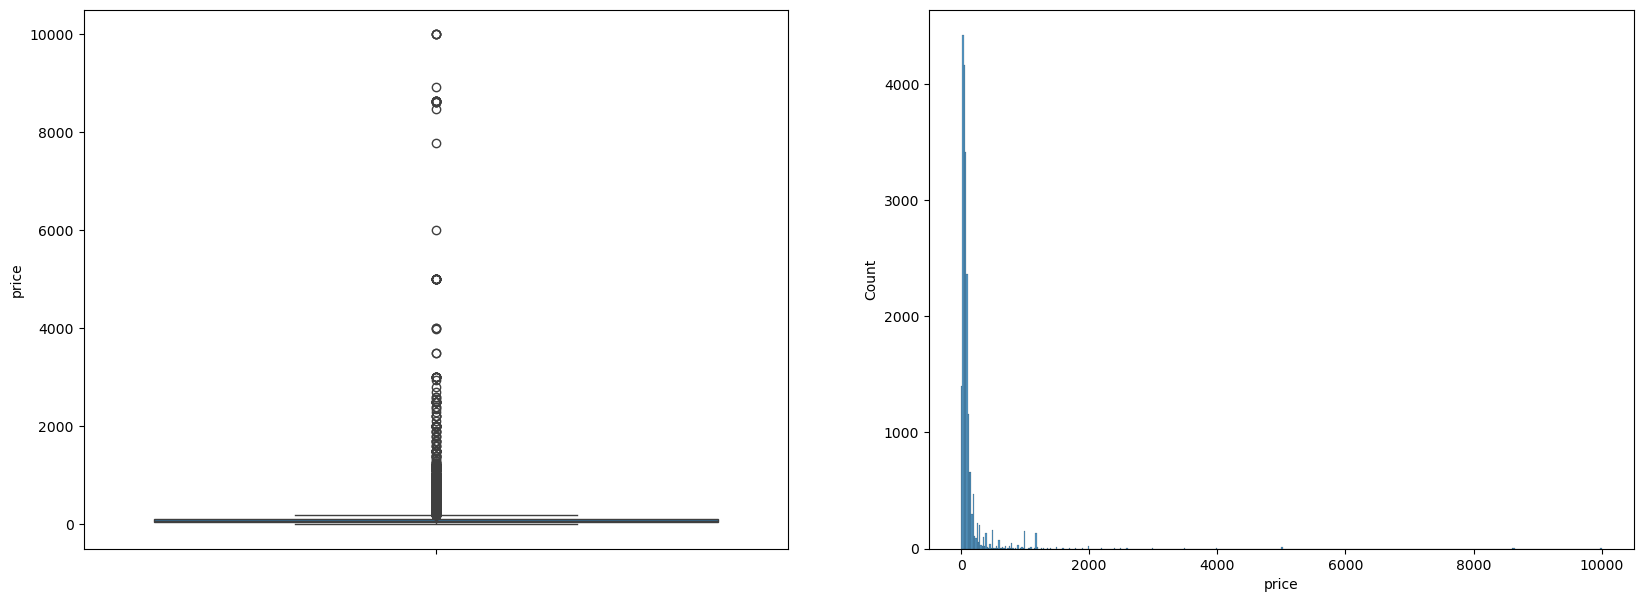

In [103]:
# generally speaking, what are prices like in Madrid?
print(df.price.describe())

fig, ax = plt.subplots(1,2, figsize=(20, 7) )
sns.boxplot(data=df, y='price', ax=ax[0])
sns.histplot(data=df, x='price', binwidth=20)

Prices go all the way up to €9,999 a night — clearly non-representative
outliers (likely misconfigured listings or extreme luxury properties) that
would distort any comparison based on medians or means. I applied a
business-logic cutoff of €200/night, which keeps the vast majority of the
market while removing the long tail that isn't relevant to a typical host.

<Axes: xlabel='price', ylabel='Count'>

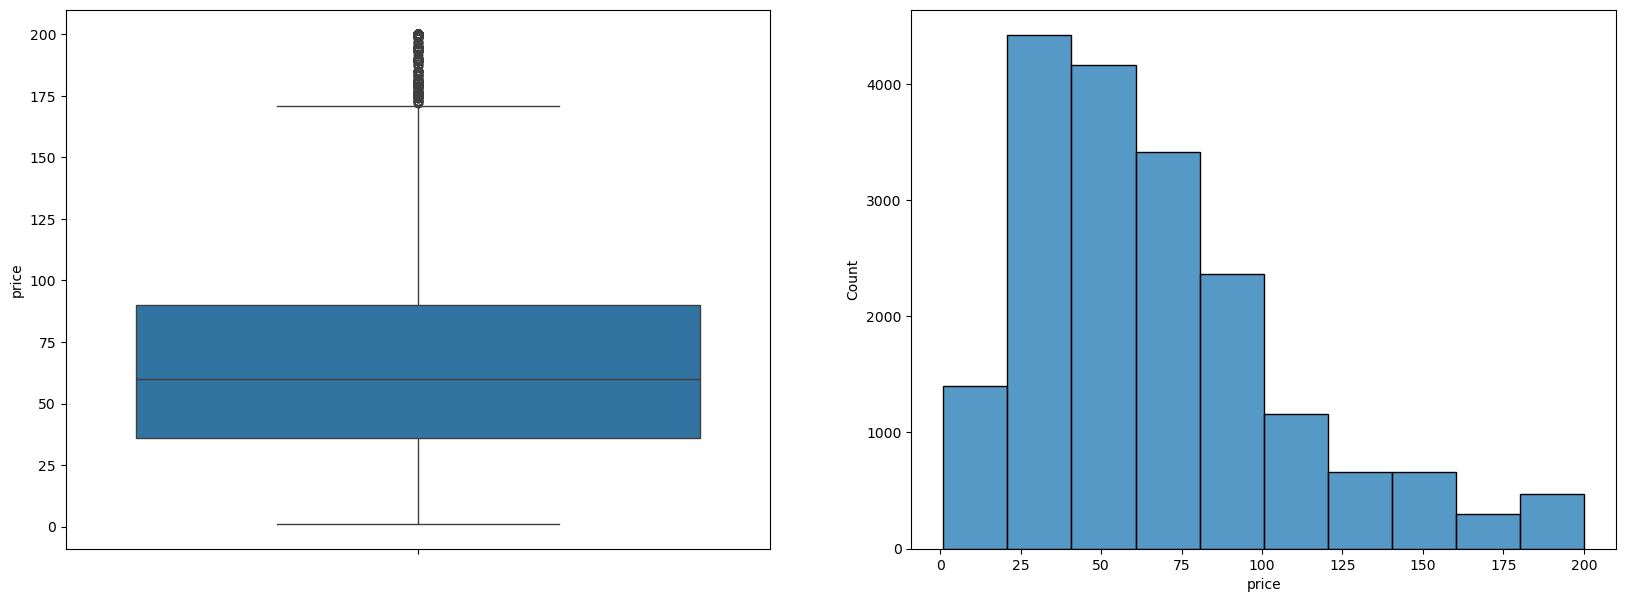

In [104]:
df_clean = df[df['price'] <= 200]

# we observe the graphics again:
fig, ax = plt.subplots(1,2, figsize=(20, 7) )
sns.boxplot(data=df_clean, y='price', ax=ax[0])
sns.histplot(data=df_clean, x='price', binwidth=20)

## We explore what the Airbnb market is like in Madrid

### Neighborhoods, property types and room types

A quick count of how many distinct neighborhoods, property types and room
types exist in the cleaned dataset, before visualizing their distribution.

In [105]:
# How many neighborhoods, types of property and types of rooms are there in Madrid?
print(f'total number of neighborhoods: {df_clean.neighbourhood.nunique()}')
print(f'total number of different property types: {df_clean.property_type.nunique()}')
print(f'total number of different room types: {df_clean.room_type.nunique()}')

total number of neighborhoods: 66
total number of different property types: 26
total number of different room types: 4


[None, None, None, None]

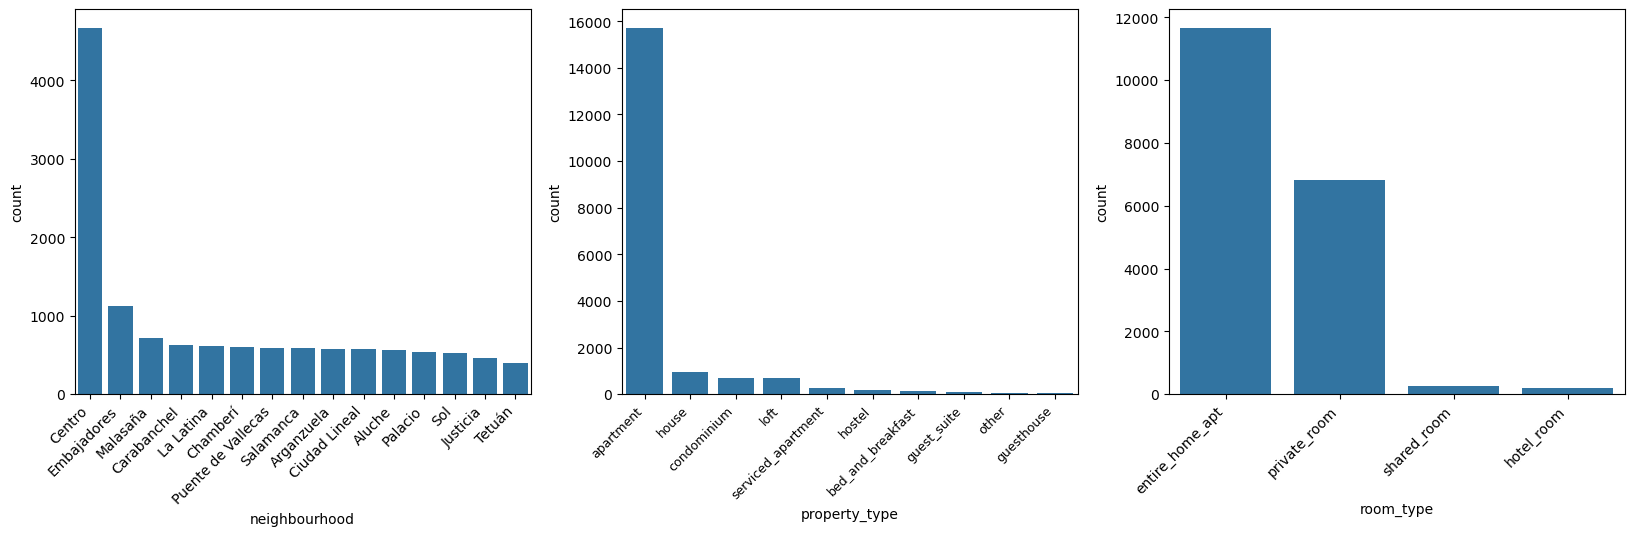

In [106]:
# we generate a countplot to see the distribution of these variables
fig, ax = plt.subplots(1,3, figsize=(20,5))
# we observe the 15 neighborhoods with the most properties
top_15_barrios = df_clean.neighbourhood.value_counts().sort_values(ascending=False).head(15).index
sns.countplot(data=df_clean[df_clean.neighbourhood.isin(top_15_barrios)], x='neighbourhood', ax=ax[0], order=top_15_barrios)
ax[0].tick_params(axis='x',rotation=45)
plt.setp(ax[0].get_xticklabels(), ha='right')
# We observe the property types
top_10_tipos_propiedad = df_clean.property_type.value_counts().sort_values(ascending=False).head(10).index
sns.countplot(data=df_clean[df_clean.property_type.isin(top_10_tipos_propiedad)], x='property_type', ax=ax[1], order = top_10_tipos_propiedad)
ax[1].tick_params(axis='x',rotation=45, labelsize=9)
plt.setp(ax[1].get_xticklabels(), ha='right')
# we observed the types of rooms
sns.countplot(data=df_clean, x='room_type', ax=ax[2], order=df_clean.room_type.value_counts().index)
ax[2].tick_params(axis='x',rotation=45)
plt.setp(ax[2].get_xticklabels(), ha='right')


## Insights:
- The Airbnb market in Madrid has 21,020 properties in total.
- The price per night of half of these properties ranges between €40 and €102 per night, with a median of €65. We also observed atypical values ​​that reach a maximum of €9,999 and a minimum of €1 per night.
- The properties are distributed among 66 different neighborhoods, with 'center' being the neighborhood with the most concentration, with almost 4,000 more properties than Embajadores, the second neighborhood with the most properties.
- There are 30 types of properties in Madrid, with apartments being the most common by far.
- There are also four types of rooms available, the most common being complete apartments and private rooms



# 2. Define the problem we want to solve

The client's original question — *"what can I do to optimize the price of
my homes?"* — is too broad to analyze directly: it doesn't say which homes,
what "optimize" means, or when the analysis should stop. Before writing any
more code, I rewrote it into a properly scoped problem, checking it against
four criteria I find useful for any data project:

- **Specific** — is the problem free of ambiguity?
- **Scope** — is it clear where the analysis starts and ends?
- **Value** — does solving it actually help the client?
- **Actionable** — can the client do something with the answer?

## Problem definition:
- The client wants recommendations to improve their housing offerings and increase prices, as well as to identify factors that may be lowering housing prices.

## Scope definition:
- The analysis will focus on apartment-type dwellings that are rented out in their entirety and that have between 1 and 3 bedrooms and a kitchen.

### Applying the scope filter

Checking the `amenities_kitchen` values before filtering, then restricting
the dataset to the listings the problem definition above actually covers:
entire apartments, 1–3 bedrooms, with a kitchen.

In [107]:
# what are the data for the amenities_kitchen variable?
df_clean.amenities_kitchen.unique()

array([1, 0])

In [108]:
conditions = (df_clean['property_type'] =='apartment') & (df_clean['room_type'] == 'entire_home_apt') & (df_clean['bedrooms'] >= 1) & (df_clean['bedrooms'] <= 3) & (df_clean['amenities_kitchen'] == 1)

In [109]:
df_study_set = df_clean[conditions]

In [110]:
# we check the new data set
print(f'property types: {df_study_set.property_type.unique()}')
print(f'room types: {df_study_set.room_type.unique()}')
print(f'number of rooms: {df_study_set.bedrooms.unique()}')
print(f'kitchen: {df_study_set.amenities_kitchen.unique()}')
print(f'max price: {df_study_set.price.max()}')

property types: <ArrowStringArray>
['apartment']
Length: 1, dtype: str
room types: <ArrowStringArray>
['entire_home_apt']
Length: 1, dtype: str
number of rooms: [3. 2. 1.]
kitchen: [1]
max price: 200.0


# 3. Define and develop the analysis roadmap

The dataset has far more variables than I could reasonably test in depth, so
I prioritized a shortlist of hypotheses across four themes — property
amenities, guest reviews, host behavior, and booking conditions — chosen for
being both plausible price drivers *and* things a host can realistically act
on.

## Hypotheses
To properly focus data storytelling, the following hypotheses have been prioritized for validation to discover how each of the following aspects—property characteristics, reviews, the host, and booking conditions—affects the price:
### According to property characteristics:
- Having internet access increases the price. Variables: amenities_wifi_internet, price
- Having a television increases the price. Variables: amenities_tv, price
- Having air conditioning increases the price. Variables: amenities_air_conditioning, price
- Having heating increases the price. Variables: amenities_heating, price

### According to reviews:
- The cleaner the property is perceived to be, the higher the price. Variables: review_scores_cleanliness
- The better the perceived check-in experience, the higher the price. Variables: review_scores_checkin, price
- The better the perceived communication with the host, the higher the price. Variables: review_scores_communication, price

### Based on host characteristics:
- Being a Superhost increases the price of the accommodations. Variables: host_is_superhost, price
- The faster the host responds to inquiries, the more expensive the accommodation will be. Variables: host_response_time, price
- The higher the host's response rate, the higher the price of the accommodation. Variables: host_response_rate, price

### Based on booking conditions:
- The stricter the cancellation policy, the lower the price. Variables: cancellation_policy, price

# 4. Gather the main insights to build the final storytelling

Below I validate each hypothesis in turn and close with a set of
prioritized, actionable recommendations for the client.

## Hypothesis validation

### According to the characteristics of the listings:

INTERNET VS PRICE:

347 listings without internet and 8680 listings with internet
Median without internet: 70.0
Median with internet: 80.0
Difference: 10.0 . median increases 14.29%
--------------------------------------------------
TV VS PRICE:

605 listings without tv and 8422 listings with tv
Median without tv: 69.0
Median with tv: 80.0
Difference: 11.0 . median increases 15.94%
--------------------------------------------------
AC VS PRICE:

1819 listings without air conditioning and 7208 listings with air conditioning
Median without air conditioning: 70.0
Median with air conditioning: 80.0
Difference: 10.0 . median increases 14.29%
--------------------------------------------------
HEATING VS PRICE:

460 listings without heating, 8567 listings with heating
Median without heating: 70.0
Median with heating: 80.0
Difference: 10.0 . median increases 14.29%


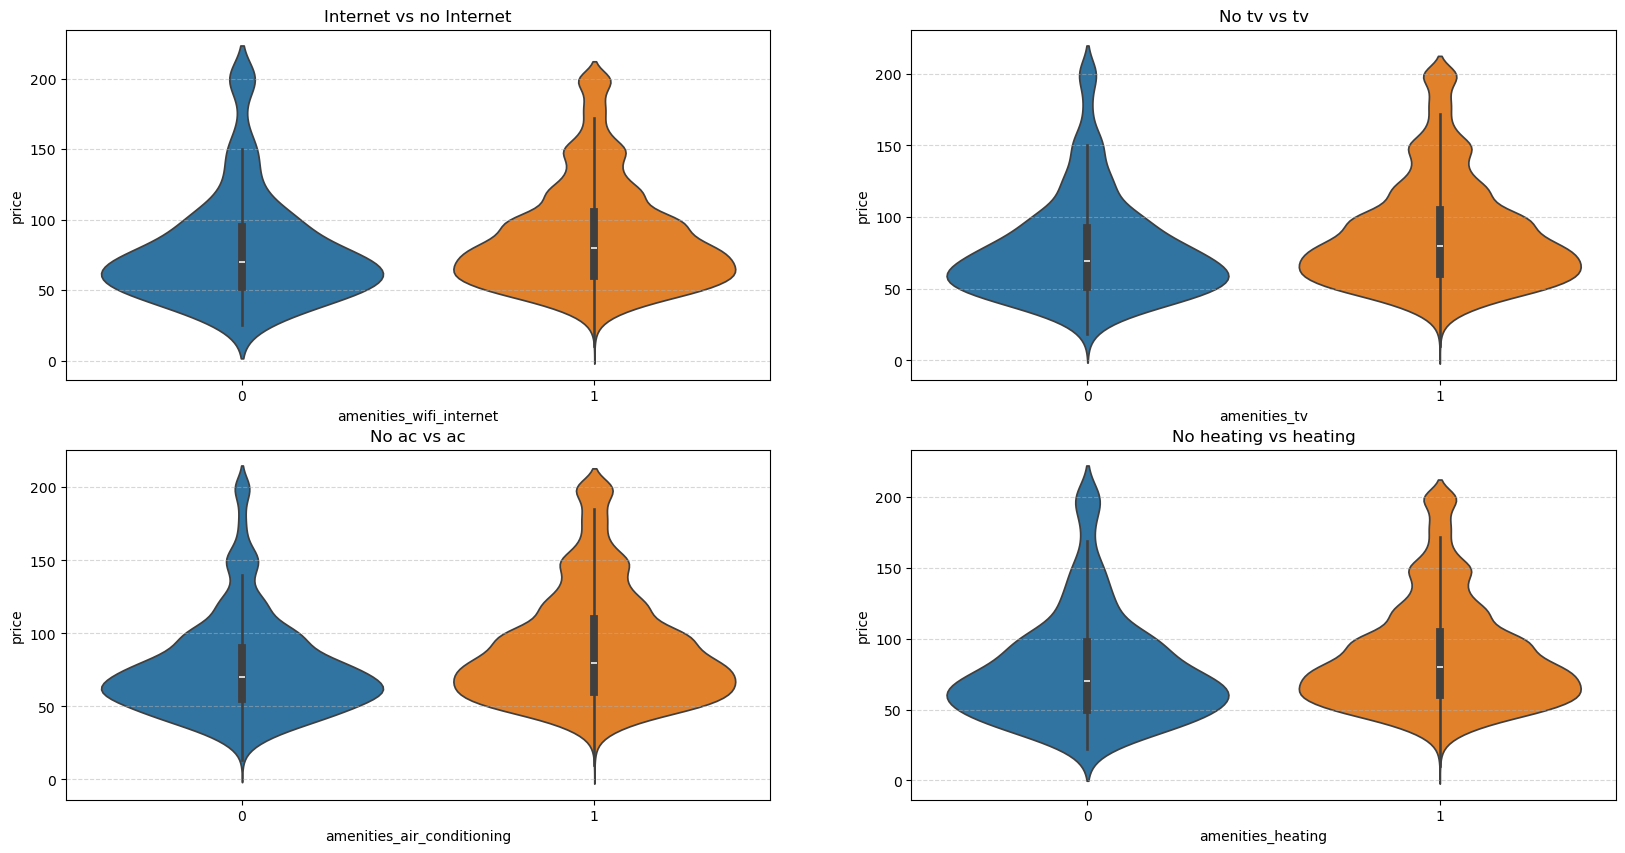

In [111]:
fig, ax = plt.subplots(2,2, figsize=(20, 10))

# no internet vs internet
sns.violinplot(
    data=df_study_set,
    x='amenities_wifi_internet',
    y='price',
    hue='amenities_wifi_internet',
    legend=False,
    ax=ax[0,0]
)
ax[0,0].set_title('Internet vs no Internet')
ax[0,0].grid(visible=True, axis='y', linestyle='--', alpha=0.5)


# no tv vs tv
sns.violinplot(
    data=df_study_set,
    x='amenities_tv',
    y='price',
    hue='amenities_tv',
    legend=False,
    ax=ax[0,1]
)
ax[0,1].set_title('No tv vs tv')
ax[0,1].grid(visible=True, axis='y', linestyle='--', alpha=0.5)

# no ac vs ac
sns.violinplot(
    data=df_study_set,
    x='amenities_air_conditioning',
    y='price',
    hue='amenities_air_conditioning',
    legend=False,
    ax=ax[1,0]
)
ax[1,0].set_title('No ac vs ac')
ax[1,0].grid(visible=True, axis='y', linestyle='--', alpha=0.5)

# no heating vs heating
sns.violinplot(
    data=df_study_set,
    x='amenities_heating',
    y='price',
    hue='amenities_heating',
    legend=False,
    ax=ax[1,1]
)
ax[1,1].set_title('No heating vs heating')
ax[1,1].grid(visible=True, axis='y', linestyle='--', alpha=0.5)

# We calculated the medians, their differences, and the value counts by category.

# internet vs price
internet_vs_price = df_study_set.groupby('amenities_wifi_internet').price.median()
internet_vs_price_counts = df_study_set.groupby('amenities_wifi_internet').size()
print('INTERNET VS PRICE:\n')
print(f'{internet_vs_price_counts.iloc[0]} listings without internet and {internet_vs_price_counts.iloc[1]} listings with internet')
print(f'Median without internet: {internet_vs_price.iloc[0]}')
print(f'Median with internet: {internet_vs_price.iloc[1]}')
print(f'Difference: {internet_vs_price.iloc[1] - internet_vs_price.iloc[0]} . median increases {((internet_vs_price.iloc[1]-internet_vs_price.iloc[0])/(internet_vs_price.iloc[0]))*100:.2f}%')
print('-'*50)

# tv vs price

tv_vs_price = df_study_set.groupby('amenities_tv').price.median()
tv_vs_price_counts = df_study_set.groupby('amenities_tv').size()
print('TV VS PRICE:\n')
print(f'{tv_vs_price_counts.iloc[0]} listings without tv and {tv_vs_price_counts.iloc[1]} listings with tv')
print(f'Median without tv: {tv_vs_price.iloc[0]}')
print(f'Median with tv: {tv_vs_price.iloc[1]}')
print(f'Difference: {tv_vs_price.iloc[1] - tv_vs_price.iloc[0]} . median increases {((tv_vs_price.iloc[1]-tv_vs_price.iloc[0])/(tv_vs_price.iloc[0]))*100:.2f}%')
print('-'*50)

# ac vs price

air_vs_price = df_study_set.groupby('amenities_air_conditioning').price.median()
air_vs_price_counts = df_study_set.groupby('amenities_air_conditioning').size()
print('AC VS PRICE:\n')
print(f'{air_vs_price_counts.iloc[0]} listings without air conditioning and {air_vs_price_counts.iloc[1]} listings with air conditioning')
print(f'Median without air conditioning: {air_vs_price.iloc[0]}')
print(f'Median with air conditioning: {air_vs_price.iloc[1]}')
print(f'Difference: {air_vs_price.iloc[1] - air_vs_price.iloc[0]} . median increases {((air_vs_price.iloc[1]-air_vs_price.iloc[0])/(air_vs_price.iloc[0]))*100:.2f}%')
print('-'*50)

# heating vs price

heating_vs_price = df_study_set.groupby('amenities_heating').price.median()
heating_vs_price_counts = df_study_set.groupby('amenities_heating').size()
print('HEATING VS PRICE:\n')
print(f'{heating_vs_price_counts.iloc[0]} listings without heating, {heating_vs_price_counts.iloc[1]} listings with heating')
print(f'Median without heating: {heating_vs_price.iloc[0]}')
print(f'Median with heating: {heating_vs_price.iloc[1]}')
print(f'Difference: {heating_vs_price.iloc[1] - heating_vs_price.iloc[0]} . median increases {((heating_vs_price.iloc[1]-heating_vs_price.iloc[0])/(heating_vs_price.iloc[0]))*100:.2f}%')

**Internet/WiFi → Price**

Homes with WiFi have a median price of €80 compared to €70 without (+14.29%), with a large sample size in both groups (347 without / 8,680 with).

The difference is consistent and representative in relative terms.

WiFi is a low-cost amenity to install and has a clear effect on price, so it should be one of the first recommendations for the client.

**TV → Price**

Homes with TVs have a median price of €80 compared to €69 for those without (+15.94%), with 605 properties without TVs and 8,422 with TVs. This is the largest relative difference of the four amenities analyzed.

Along with Wi-Fi, this is the improvement with the best expected cost/benefit ratio. It is recommended to prioritize its installation in properties that do not yet include it.

**AC → Price**

Homes with air conditioning have a median price of €80 compared to €70 without (+14.29%), with 1,819 properties without A/C and 7,208 with A/C.

Recommended as a medium-term upgrade. Since it generally involves a larger investment than WiFi or TV, it can be prioritized after lower-cost amenities.

**Heating → Price**

Apartments with heating have a median price of €80 compared to €70 without (+14.29%), with 460 properties without heating and 8,567 with it.

This effect is in line with the other amenities. Given that heating is practically expected by guests in Madrid, its absence could also be negatively impacting the overall perception of the property, beyond just the price.

### According to the reviews

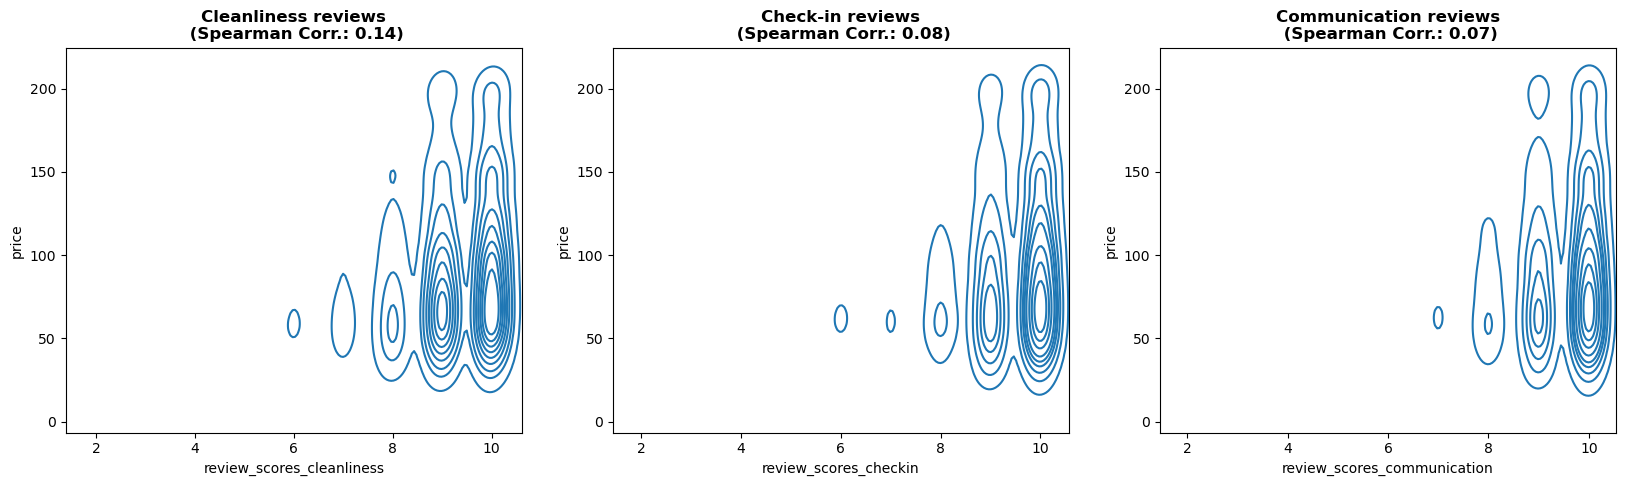

In [112]:
fig, ax = plt.subplots(1,3, figsize=(20, 5))

# Cleanliness reviews

corr_coef = df_study_set.review_scores_cleanliness.corr(df_study_set.price, method='spearman')

sns.kdeplot(
    data=df_study_set,
    x='review_scores_cleanliness',
    y='price',
    legend=False,
    ax=ax[0]
)
ax[0].set_title(f'Cleanliness reviews\n (Spearman Corr.: {corr_coef:.2f})', fontsize=12, fontweight='bold')


# Check-in reviews

corr_coef = df_study_set.review_scores_checkin.corr(df_study_set.price, method='spearman')

sns.kdeplot(
    data=df_study_set,
    x='review_scores_checkin',
    y='price',
    legend=False,
    ax=ax[1]
)
ax[1].set_title(f'Check-in reviews\n (Spearman Corr.: {corr_coef:.2f})', fontsize=12, fontweight='bold')

# Communication reviews

corr_coef = df_study_set.review_scores_communication.corr(df_study_set.price, method='spearman')

sns.kdeplot(
    data=df_study_set,
    x='review_scores_communication',
    y='price',
    legend=False,
    ax=ax[2]
)
ax[2].set_title(f'Communication reviews\n (Spearman Corr.: {corr_coef:.2f})', fontsize=12, fontweight='bold');

**Cleanliness reviews → Price**

The Spearman correlation between cleanliness score and price is 0.14, a virtually nonexistent relationship.

The graph visually confirms this: scores are almost entirely concentrated between 8 and 10, and within that range, prices are similarly distributed without a clear trend pattern.

Cleanliness does not appear to be a price lever. It is reasonable to interpret it as a minimum standard expected by guests; its absence likely penalizes occupancy or future reviews more than the price the host sets.

**Check-in reviews → Price**

The Spearman correlation is 0.08, which is essentially zero. As with cleanliness, the scores are highly concentrated in the 8-10 range, leaving little room to observe a trend even if one existed.

There is no evidence that the check-in experience, as rated by guests, influences the price. It is not recommended to prioritize it as a price optimization factor, although it may still be relevant to overall guest satisfaction.

The Spearman correlation is 0.07, the lowest of the four continuous variables analyzed in this section and practically zero.

Communication with the host, measured through reviews, shows no relationship with the price. This result is consistent with that obtained for `host_response_rate` both variables describe a similar aspect of host behavior, and neither appears to have any bearing on the price set.

### According to host characteristics

SUPERHOST VS PRICE:

6850 not superhost, 2177 superhost
Median not superhost: 75.5
Median superhost: 85.0
Difference: 9.5 . Median increases 12.58%
--------------------------------------------------
RESPONSE TIME VS PRICE:

6244 within an hour, 945 within a few hours, 561 within a day, 122 a few days or more
Median within an hour: 80.0
Median within a few hours: 80.0
Median within a day: 85.0
Median a few days or more: 77.0
Median difference between within an hour and a few days or more: 3.0 . Median increases: 3.90%
Median difference between within a day and a few days or more: 8.0 . Median increases: 10.39%


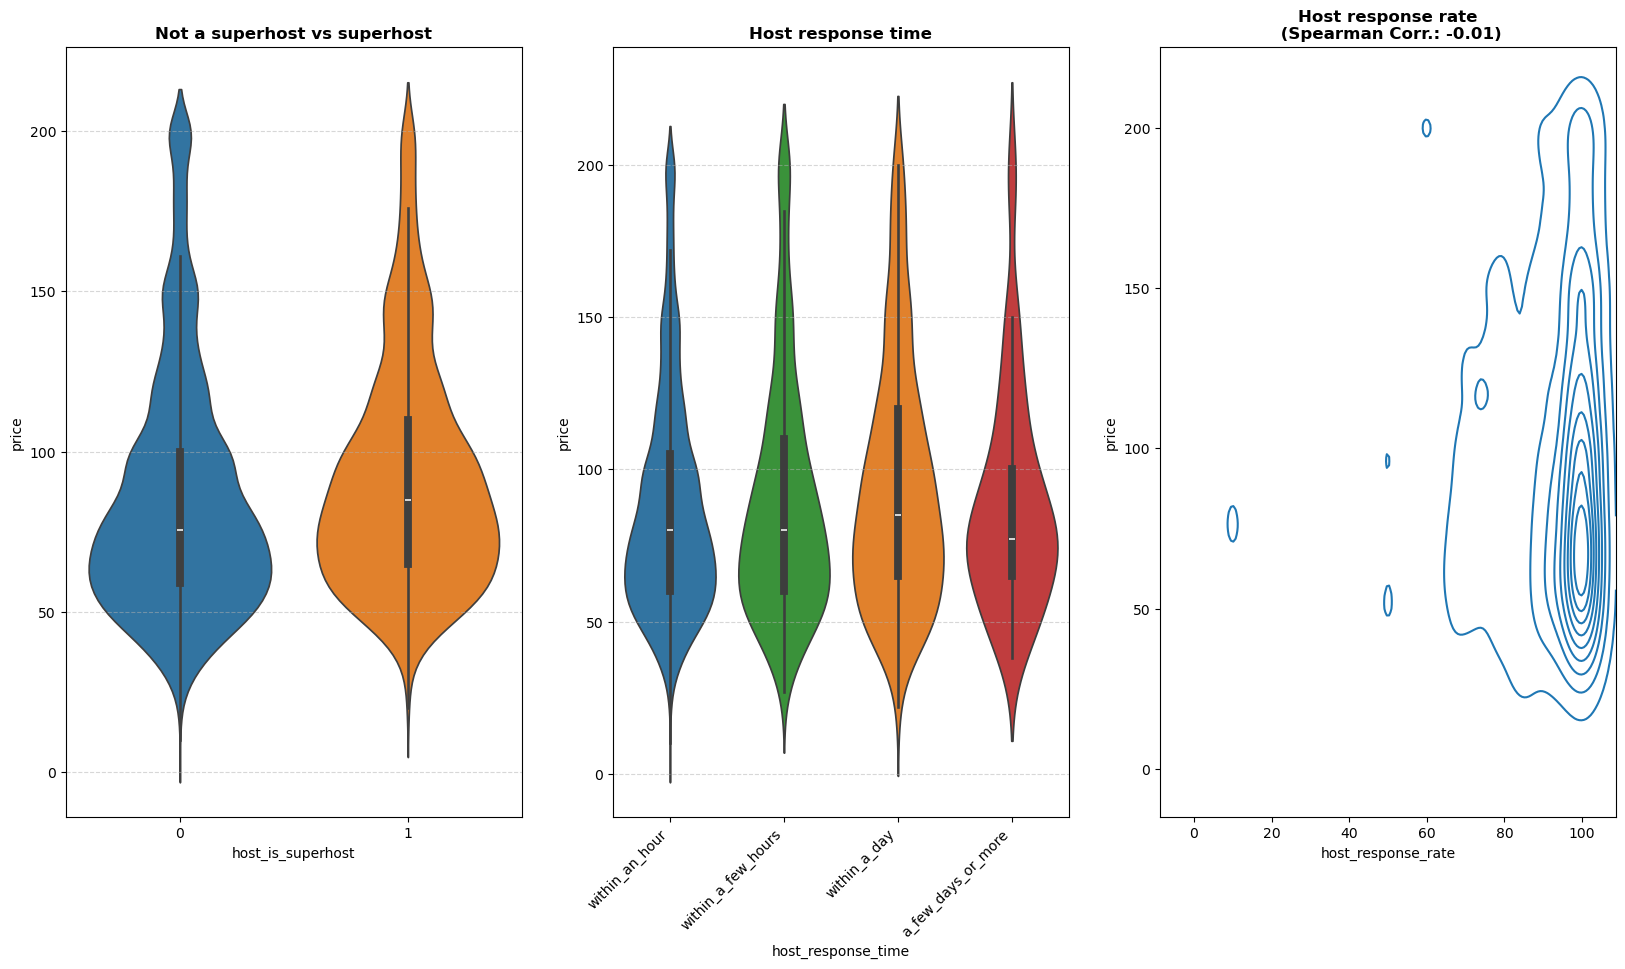

In [113]:
fig, ax = plt.subplots(1,3, figsize=(20, 10))

# Not a superhost vs superhost
sns.violinplot(
    data=df_study_set,
    x='host_is_superhost',
    y='price',
    hue='host_is_superhost',
    legend=False,
    ax=ax[0]
)
ax[0].set_title('Not a superhost vs superhost', fontweight='bold')
ax[0].grid(visible=True, axis='y', linestyle='--', alpha=0.5)


# Host response time
order = ['within_an_hour', 'within_a_few_hours', 'within_a_day', 'a_few_days_or_more']
sns.violinplot(
    data=df_study_set,
    x='host_response_time',
    y='price',
    hue='host_response_time',
    legend=False,
    ax=ax[1],
    order=order
)
ax[1].set_title('Host response time', fontweight='bold')
for label in ax[1].get_xticklabels():
    label.set_rotation(45)
    label.set_ha('right')
ax[1].grid(visible=True, axis='y', linestyle='--', alpha=0.5)

# host response rate

corr_coef = df_study_set.host_response_rate.corr(df_study_set.price, method='spearman')

sns.kdeplot(
    data=df_study_set,
    x='host_response_rate',
    y='price',
    legend=False,
    ax=ax[2]
)
ax[2].set_title(f'Host response rate\n (Spearman Corr.: {corr_coef:.2f})', fontsize=12, fontweight='bold')

# host vs superhost stats
superhost_vs_price = df_study_set.groupby('host_is_superhost').price.median()
superhost_vs_price_counts = df_study_set.groupby('host_is_superhost').size()
print('SUPERHOST VS PRICE:\n')
print(f'{superhost_vs_price_counts.iloc[0]} not superhost, {superhost_vs_price_counts.iloc[1]} superhost')
print(f'Median not superhost: {superhost_vs_price.iloc[0]}')
print(f'Median superhost: {superhost_vs_price.iloc[1]}')
print(f'Difference: {superhost_vs_price.iloc[1] - superhost_vs_price.iloc[0]} . Median increases {((superhost_vs_price.iloc[1]-superhost_vs_price.iloc[0])/(superhost_vs_price.iloc[0]))*100:.2f}%')
print('-'*50)

# response time vs price
response_time_vs_price = df_study_set.groupby('host_response_time').price.median()
response_time_vs_price_counts = df_study_set.groupby('host_response_time').size()
print('RESPONSE TIME VS PRICE:\n')
print(f"{response_time_vs_price_counts.loc['within_an_hour']} within an hour, {response_time_vs_price_counts.loc['within_a_few_hours']} within a few hours, {response_time_vs_price_counts.loc['within_a_day']} within a day, {response_time_vs_price_counts.loc['a_few_days_or_more']} a few days or more")
print(f"Median within an hour: {response_time_vs_price.loc['within_an_hour']}")
print(f"Median within a few hours: {response_time_vs_price.loc['within_a_few_hours']}")
print(f"Median within a day: {response_time_vs_price.loc['within_a_day']}")
print(f"Median a few days or more: {response_time_vs_price.loc['a_few_days_or_more']}")
print(f"Median difference between within an hour and a few days or more: {response_time_vs_price.loc['within_an_hour']-response_time_vs_price.loc['a_few_days_or_more']} . Median increases: {((response_time_vs_price.loc['within_an_hour']-response_time_vs_price.loc['a_few_days_or_more'])/(response_time_vs_price.loc['a_few_days_or_more']))*100:.2f}%")
print(f"Median difference between within a day and a few days or more: {response_time_vs_price.loc['within_a_day']-response_time_vs_price.loc['a_few_days_or_more']} . Median increases: {((response_time_vs_price.loc['within_a_day']-response_time_vs_price.loc['a_few_days_or_more'])/(response_time_vs_price.loc['a_few_days_or_more']))*100:.2f}%")

**Being a Superhost → Price**

Hosts with superhost status have a median price of €85 compared to €75.5 for those who are not (+12.58%), with a robust sample size in both groups (6,850 non-superhosts / 2,177 superhosts).

Achieving superhost status is associated with a higher price. It is an actionable, though indirect, recommendation.

**Host Response Time → Price**

Contrary to what was expected from the initial hypothesis, listings whose host responds within an hour do not have the highest price (median €80); the "within_a_day" category surpasses it (€85). The difference between the fastest end ("within_an_hour") and the slowest ("a_few_days_or_more") is only +€3 (+3.90%), which is much weaker than the effect observed in amenities.

There is insufficient evidence to recommend response time as a price lever.

**Host Response Rate → Price**

The Spearman correlation is -0.01, practically zero. The plot shows that the vast majority of listings have a very high response rate (concentrated between 90 and 100), leaving very little variability to detect any relationship with price.

There is no evidence that the host response rate affects the price. Combined with the result of `host_response_time` (weak effect, +3.9%) and `review_scores_communication` (0.07 correlation), the set of variables related to host responsiveness is dismissed as a relevant lever for this phase of the analysis focused on price.

### According to booking conditions

CANCELLATION POLICY VS PRICE:

2109 flexible, 3219 moderate, 3579 strict with grace period, 69 super strict level 30, 51 super strict level 60
Median flexible: 80.0
Median moderate: 80.0
Median strict with grace period: 76.0
Median super strict level 30: 75.0
Median super strict level 60: 52.0
Median difference between flexible and super strict level 60: 28.0 . Median increases: 53.85%


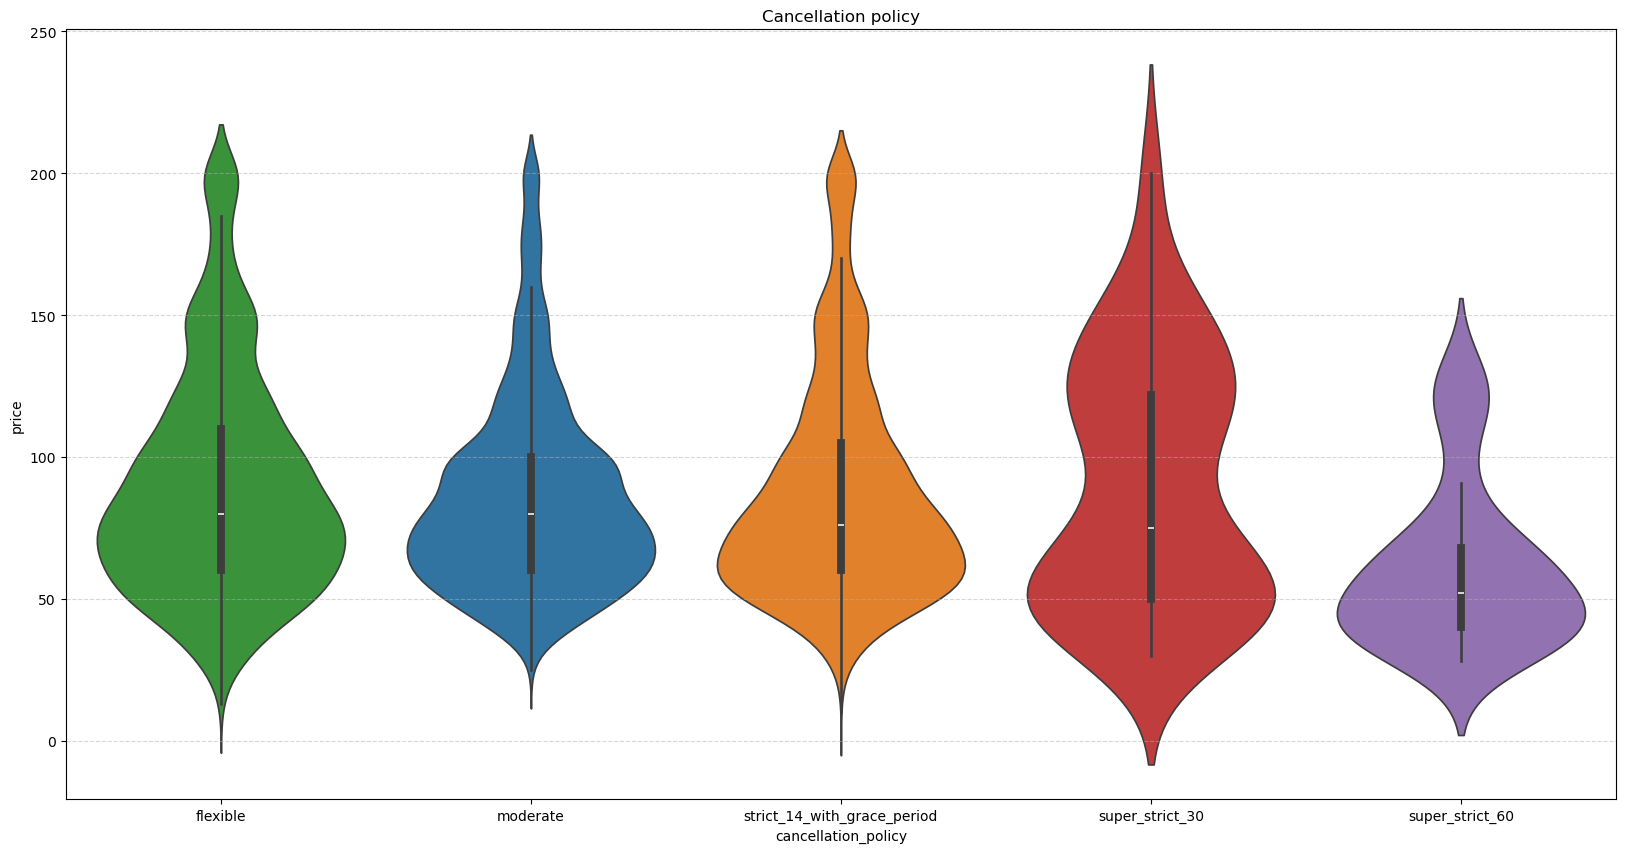

In [114]:
fig, ax = plt.subplots(figsize=(20, 10))
order=['flexible','moderate','strict_14_with_grace_period','super_strict_30','super_strict_60']

sns.violinplot(
    data=df_study_set,
    x='cancellation_policy',
    y='price',
    hue='cancellation_policy',
    legend=False,
    order=order
)
ax.set_title('Cancellation policy')
ax.grid(visible=True, axis='y', linestyle='--', alpha=0.5)

# stats:
cancellation_policy_vs_price = df_study_set.groupby('cancellation_policy').price.median()
cancellation_policy_vs_price_counts = df_study_set.groupby('cancellation_policy').size()
print('CANCELLATION POLICY VS PRICE:\n')
print(f'{cancellation_policy_vs_price_counts.loc['flexible']} flexible, {cancellation_policy_vs_price_counts.loc['moderate']} moderate, {cancellation_policy_vs_price_counts.loc['strict_14_with_grace_period']} strict with grace period, {cancellation_policy_vs_price_counts.loc['super_strict_30']} super strict level 30, {cancellation_policy_vs_price_counts.loc['super_strict_60']} super strict level 60')
print(f'Median flexible: {cancellation_policy_vs_price.loc['flexible']}')
print(f'Median moderate: {cancellation_policy_vs_price.loc['moderate']}')
print(f'Median strict with grace period: {cancellation_policy_vs_price.loc['strict_14_with_grace_period']}')
print(f'Median super strict level 30: {cancellation_policy_vs_price.loc['super_strict_30']}')
print(f'Median super strict level 60: {cancellation_policy_vs_price.loc['super_strict_60']}')
print(f'Median difference between flexible and super strict level 60: {cancellation_policy_vs_price.loc['flexible']-cancellation_policy_vs_price.loc['super_strict_60']} . Median increases: {((cancellation_policy_vs_price.loc['flexible']-cancellation_policy_vs_price.loc['super_strict_60'])/(cancellation_policy_vs_price.loc['super_strict_60']))*100:.2f}%')

**Cancellation Policy → Price**

The median price decreases from €80 for the "flexible" policy to €52 for "super_strict_60" (a difference of €28, or 53.85%). However, the strictest categories have a very small sample size (69 and 51 listings, compared to more than 2,000 for flexible and moderate), so this difference must be interpreted with caution.

It is likely that this relationship is not causal in the direction of "strict policy → low price", but rather the opposite: listings with a certain price profile might tend to choose different policies. Before recommending a policy change to the client, it would be necessary to validate this effect by controlling for other variables (property type, neighborhood) and with a larger sample size in the stricter categories.

## CONCLUSION

Physical amenities (TV, WiFi, heating, A/C) are the group with the strongest and most consistent effect on price, while everything related to the host's behavior or reputation—except for superhost status—shows a weak or non-existent effect. This suggests that, for the client, the most reliable price levers lie in the physical characteristics of the listing, rather than in how they manage the relationship with their guests.

Therefore, the recommendations for the client are:

1. **Prioritize the installation of physical amenities** in properties that do not yet have them, starting with those that have the highest relative impact: TV (+15.94%), WiFi (+14.29%), and heating (+14.29%). These are low-cost improvements with a clear effect backed by a large sample size.
2. **Evaluate the installation of air conditioning** (+14.29%), considering that its installation cost is higher than other amenities and may require a case-by-case assessment.
3. **Work steadily towards superhost status** (+12.58%), understanding that it is not an immediate change but rather the result of maintaining various Airbnb requirements.
4. **Do not prioritize** investment or effort in improving the host's response time or rate, nor in communication, check-in, or cleanliness scores as a pricing strategy: the data shows no relevant relationship with price for any of these factors. This does not mean they do not matter for the guest experience, only that they are not an effective lever if the goal is to increase the price.
5. **Approach the cancellation policy with caution**: although the observed difference is the largest in the entire analysis (+53.85%), it likely reflects reverse causality (price influences the policy, not the other way around) and relies on categories with very few listings. Acting on it is not recommended without additional analysis.